# Notebook 1 — Dataset Generation: Workflow Guide

## Purpose
Prepare the pharmacy-label dataset used by the later detection and reconstruction experiments.

## Flow
1. Set up the Colab environment, mount Google Drive, and check GPU availability.
2. Upload and extract the source archive, then inspect the folder structure and image properties.
3. Inspect available annotation files and identify usable image/label pairs.
4. Locate package regions and generate crops where supported by the notebook's detection steps.
5. Create output folders and define the artificial-damage and mask-generation procedures.
6. Generate the paired clean, damaged, and mask data at the configured 416 × 416 resolution.
7. Inspect example outputs and review the generated damage-type metadata.

## Before running
Run cells in order. Confirm that the uploaded archive is the intended dataset, check the Drive paths and available storage, and visually inspect samples to verify that images and masks correspond.

## Output
The prepared dataset and associated metadata are saved to the paths configured in the notebook. Check the output-path cells for exact locations.

## Reproducibility
This notebook depends on the input archive and Colab/Drive environment. Results may change if the source data, random seed, or damage-generation settings change.


Preparing the dataset


In [1]:
# prepare environment and mount google drive

import os
import glob
import random
import shutil
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from google.colab import drive
drive.mount('/content/drive')

print("Environment is ready")

Mounted at /content/drive
Environment is ready


Checking GPU ready or not:

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not enabled")

PyTorch version: 2.11.0+cpu
CUDA available: False
GPU is not enabled


Uploading Dataset:


In [3]:
from google.colab import files

uploaded = files.upload()

print("uploaded")

for name in uploaded.keys():
    print(name)

Saving Emcure.v7i.yolov8.zip to Emcure.v7i.yolov8.zip
uploaded
Emcure.v7i.yolov8.zip


extract dataset:


In [4]:
import zipfile
import os

zip_files = []

for name in uploaded.keys():
    if name.lower().endswith(".zip"):
        zip_files.append(name)

if len(zip_files) == 0:
    raise FileNotFoundError("No ZIP file was uploaded")

zip_path = zip_files[0]

extract_dir = "/content/emcure_raw"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Dataset extracted to:", extract_dir)

Dataset extracted to: /content/emcure_raw


finding folders:


In [5]:
for root, dirs, files in os.walk(extract_dir):

    level = root.replace(extract_dir, "").count(os.sep)

    if level <= 2:

        print("    " * level + os.path.basename(root) + "/")

        for file in files[:10]:
            print("    " * (level + 1) + file)

emcure_raw/
    README.dataset.txt
    README.roboflow.txt
    data.yaml
    train/
        labels/
            20220627_115248_jpg.rf.ec453e45c2c78a3cc3ab19c401c5b7d5.txt
            20220627_154225_jpg.rf.755f6e08714aed830d40c9f86c4daa92.txt
            20220627_123602_jpg.rf.6ca260396f93b0626b656a8b52e275e2.txt
            20220627_153047_jpg.rf.49c044d99fc64a047e2813af9142a96e.txt
            20221010_153452_jpg.rf.9e0137fc52d36be2c6bf3998298770be.txt
            20221010_145505_jpg.rf.9f4417e8162107a50c279b39935673c0.txt
            20221010_150956_jpg.rf.8e9b80d937a13626ae986c42b178acf3.txt
            20220627_161752_jpg.rf.bd74d2fb5d7bbf29060211449c4d25c4.txt
            20220627_123956_jpg.rf.bfe55b08000f72069f9b6783e4ed0aa5.txt
            20220627_153713_jpg.rf.3aab45953530e15d22c761d1f5e84935.txt
        images/
            20221010_130803_jpg.rf.79a85796e187443b4e2f774f33c81572.jpg
            20220627_171212_jpg.rf.2dd21248c510fe11ddd89eaee208ee3b.jpg
            20221010

In [6]:
image_extensions = ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]

all_images = []

for ext in image_extensions:
    files = glob.glob(
        os.path.join(extract_dir, "**", ext),
        recursive=True
    )

    all_images.extend(files)

all_images = sorted(all_images)

print("Total images found:", len(all_images))

print("\nFirst 10 images:")

for path in all_images[:10]:
    print(path)

Total images found: 7709

First 10 images:
/content/emcure_raw/test/images/20220627_114508_jpg.rf.10ad83f118a87e7c4e13cb6215167a27.jpg
/content/emcure_raw/test/images/20220627_114625_jpg.rf.40c91de180a1ce5ec6d2927911b2ae3a.jpg
/content/emcure_raw/test/images/20220627_114816_jpg.rf.c8bc42dc5085f30c2cc119ff63305125.jpg
/content/emcure_raw/test/images/20220627_115318_jpg.rf.783c24164f9d5bb790ec0bef72aa9966.jpg
/content/emcure_raw/test/images/20220627_115459_jpg.rf.52b2a6bdfa0fef571cc99247d3d7a73a.jpg
/content/emcure_raw/test/images/20220627_115544_jpg.rf.4c72515d4b5761c769bf2609b95e6d06.jpg
/content/emcure_raw/test/images/20220627_115707_jpg.rf.79b69a69e3a83925d141607758b08c37.jpg
/content/emcure_raw/test/images/20220627_120645_jpg.rf.6f624d3103c84ceb3736fb7a36b0f021.jpg
/content/emcure_raw/test/images/20220627_120742_jpg.rf.a3a7ca8dbff0660774bc4da05bcee5e5.jpg
/content/emcure_raw/test/images/20220627_120951_jpg.rf.801e289345f29c2bad345644b712cad8.jpg


checking img properties:

In [7]:
sample_paths = all_images[:min(500, len(all_images))]

widths = []
heights = []
modes = []

for path in sample_paths:

    try:
        img = Image.open(path)

        widths.append(img.width)
        heights.append(img.height)
        modes.append(img.mode)

    except Exception:
        print("Could not read:", path)

print("Number of images checked:", len(widths))

print("\nWidth")
print("Minimum:", min(widths))
print("Maximum:", max(widths))
print("Average:", np.mean(widths))

print("\nHeight")
print("Minimum:", min(heights))
print("Maximum:", max(heights))
print("Average:", np.mean(heights))

print("\nImage modes")
print(pd.Series(modes).value_counts())

Number of images checked: 500

Width
Minimum: 416
Maximum: 416
Average: 416.0

Height
Minimum: 416
Maximum: 416
Average: 416.0

Image modes
RGB    500
Name: count, dtype: int64


seeing random samples:

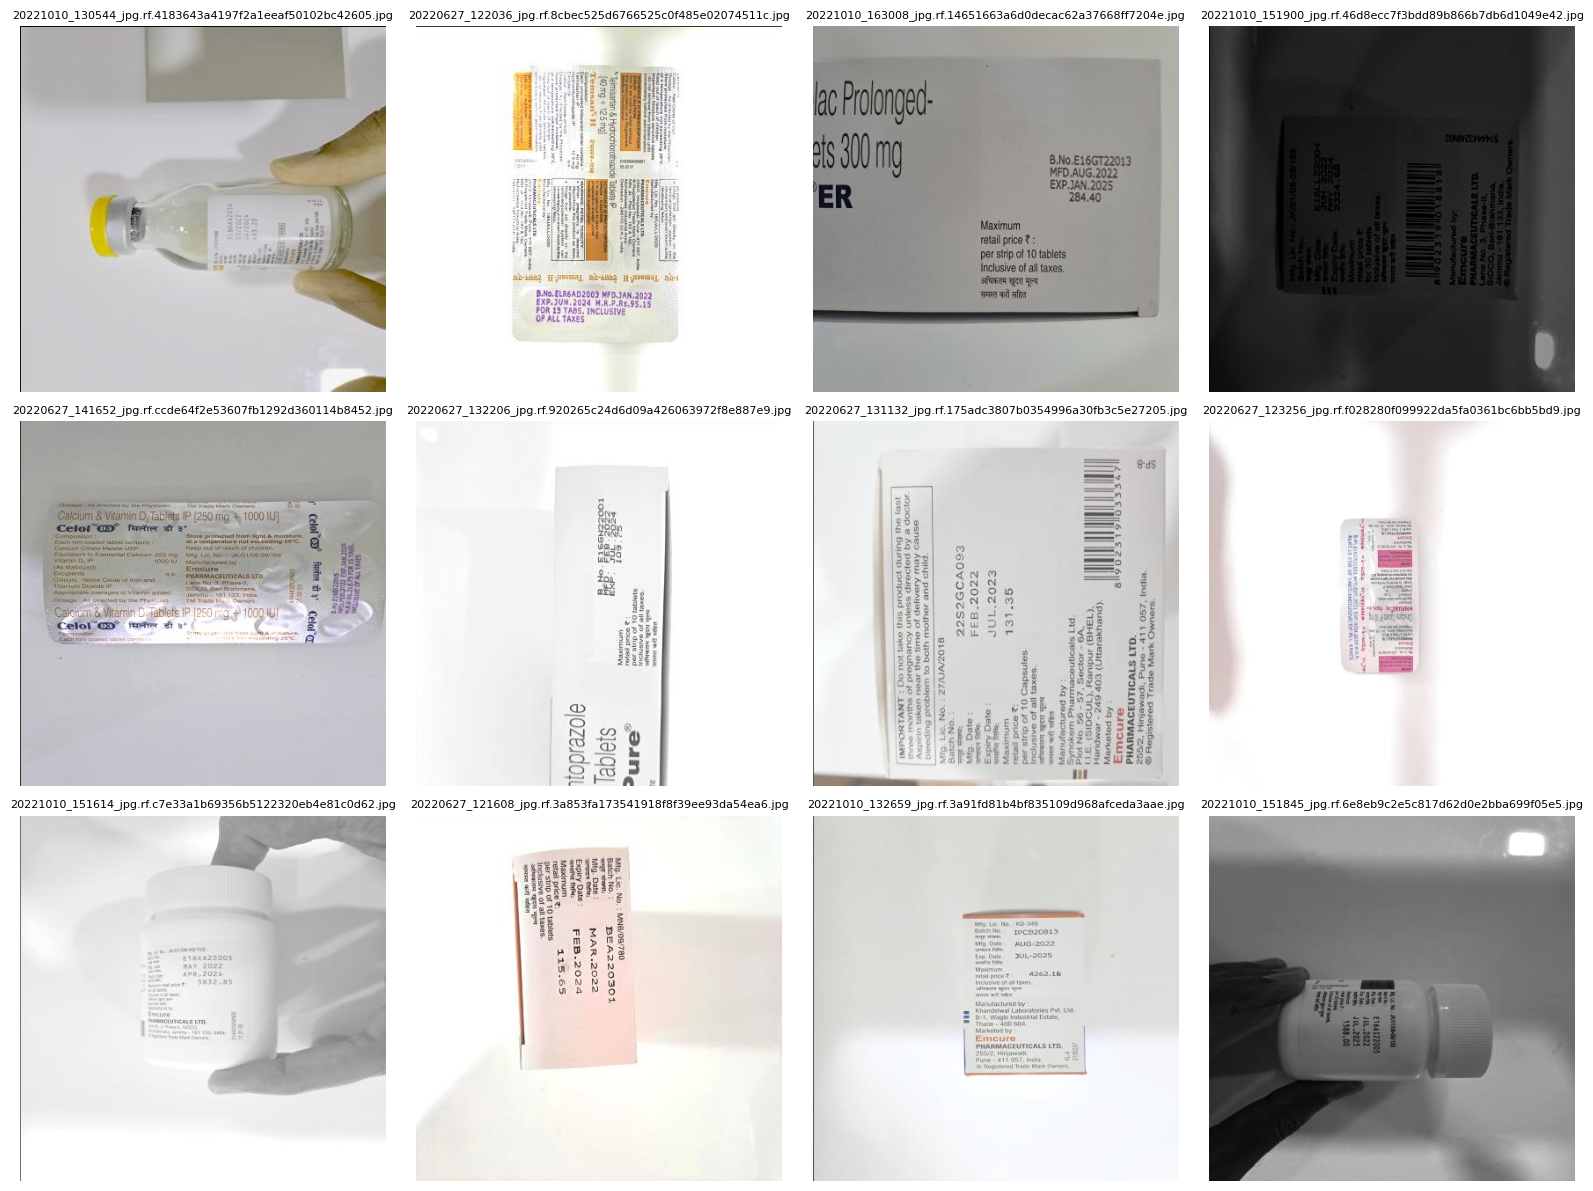

In [8]:
random.seed(42)

num_samples = min(12, len(all_images))

sample_paths = random.sample(all_images, num_samples)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

axes = axes.flatten()

for ax, path in zip(axes, sample_paths):

    img = Image.open(path).convert("RGB")

    ax.imshow(img)
    ax.set_title(os.path.basename(path), fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Phase 2

Some txt files are README files, so I will check which files actually contain YOLO annotations.

In [9]:
yolo_files = []

for file in label_files:

    try:
        with open(file, "r") as f:
            lines = f.readlines()

        is_yolo = True

        for line in lines:

            line = line.strip()

            if line == "":
                continue

            values = line.split()

            if len(values) != 5:
                is_yolo = False
                break

            for value in values:
                float(value)

        if is_yolo:
            yolo_files.append(file)

    except:
        pass

print("YOLO label files:", len(yolo_files))

NameError: name 'label_files' is not defined

 understand their format.

In [ ]:
for file in yolo_files[:5]:

    print("\nFile:", os.path.basename(file))

    with open(file, "r") as f:
        lines = f.readlines()

    for line in lines[:5]:
        print(line.strip())

YAML files found:
/content/emcure_raw/data.yaml


In [ ]:
# Print the dataset YAML

if yaml_files:

    yaml_path = yaml_files[0]

    print("\n" + "=" * 60)
    print("DATASET YAML")
    print("=" * 60)

    with open(yaml_path, "r", encoding="utf-8") as f:
        print(f.read())


DATASET YAML
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['Batch-stamps']

roboflow:
  workspace: emcure-uxbvg
  project: emcure
  version: 7
  license: CC BY 4.0
  url: https://universe.roboflow.com/emcure-uxbvg/emcure/dataset/7


labels present?

In [ ]:
label_dict = {}

for label_file in yolo_files:

    name = os.path.basename(label_file)
    stem = os.path.splitext(name)[0]

    label_dict[stem] = label_file


image_label_pairs = []
images_without_labels = []

for image_path in all_images:

    name = os.path.basename(image_path)
    stem = os.path.splitext(name)[0]

    if stem in label_dict:

        image_label_pairs.append(
            (image_path, label_dict[stem])
        )

    else:
        images_without_labels.append(image_path)


print("Images with labels:", len(image_label_pairs))
print("Images without labels:", len(images_without_labels))

Total images: 7709
Images with YOLO labels: 7708
Images without YOLO labels: 1


In [ ]:
# Check the first 10 matched pairs

for image_path, label_path in image_label_pairs[:10]:
    print("IMAGE :", os.path.basename(image_path))
    print("LABEL :", os.path.basename(label_path))
    print("MATCH :", os.path.splitext(os.path.basename(image_path))[0] ==
                  os.path.splitext(os.path.basename(label_path))[0])
    print()

IMAGE : 20220627_114508_jpg.rf.10ad83f118a87e7c4e13cb6215167a27.jpg
LABEL : 20220627_114508_jpg.rf.10ad83f118a87e7c4e13cb6215167a27.txt
MATCH : True

IMAGE : 20220627_114625_jpg.rf.40c91de180a1ce5ec6d2927911b2ae3a.jpg
LABEL : 20220627_114625_jpg.rf.40c91de180a1ce5ec6d2927911b2ae3a.txt
MATCH : True

IMAGE : 20220627_114816_jpg.rf.c8bc42dc5085f30c2cc119ff63305125.jpg
LABEL : 20220627_114816_jpg.rf.c8bc42dc5085f30c2cc119ff63305125.txt
MATCH : True

IMAGE : 20220627_115318_jpg.rf.783c24164f9d5bb790ec0bef72aa9966.jpg
LABEL : 20220627_115318_jpg.rf.783c24164f9d5bb790ec0bef72aa9966.txt
MATCH : True

IMAGE : 20220627_115459_jpg.rf.52b2a6bdfa0fef571cc99247d3d7a73a.jpg
LABEL : 20220627_115459_jpg.rf.52b2a6bdfa0fef571cc99247d3d7a73a.txt
MATCH : True

IMAGE : 20220627_115544_jpg.rf.4c72515d4b5761c769bf2609b95e6d06.jpg
LABEL : 20220627_115544_jpg.rf.4c72515d4b5761c769bf2609b95e6d06.txt
MATCH : True

IMAGE : 20220627_115707_jpg.rf.79b69a69e3a83925d141607758b08c37.jpg
LABEL : 20220627_115707_jpg.rf.7

In [10]:


sample_pairs = random.sample(
    image_label_pairs,
    min(10, len(image_label_pairs))
)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for ax, (image_path, label_path) in zip(axes, sample_pairs):

    img = Image.open(image_path).convert("RGB")
    img_np = np.array(img)

    h, w = img_np.shape[:2]

    ax.imshow(img_np)

    with open(label_path, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    for line in lines:

        class_id, xc, yc, bw, bh = map(float, line.split())

        x1 = (xc - bw / 2) * w
        y1 = (yc - bh / 2) * h
        x2 = (xc + bw / 2) * w
        y2 = (yc + bh / 2) * h

        rect = plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            linewidth=2
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            y1,
            f"class {int(class_id)}",
            fontsize=8
        )

    ax.axis("off")

plt.tight_layout()
plt.show()

NameError: name 'image_label_pairs' is not defined

In [11]:
# basic image properties

from collections import Counter

sizes = []
channels = []

for image_path in all_images:
    try:
        with Image.open(image_path) as img:
            sizes.append(img.size)
            channels.append(img.mode)
    except:
        pass

print("Number of readable images:", len(sizes))

print("\nMost common image sizes:")
for size, count in Counter(sizes).most_common(15):
    print(size, ":", count)

print("\nImage modes:")
print(Counter(channels))

Number of readable images: 7709

Most common image sizes:
(416, 416) : 7709

Image modes:
Counter({'RGB': 7709})


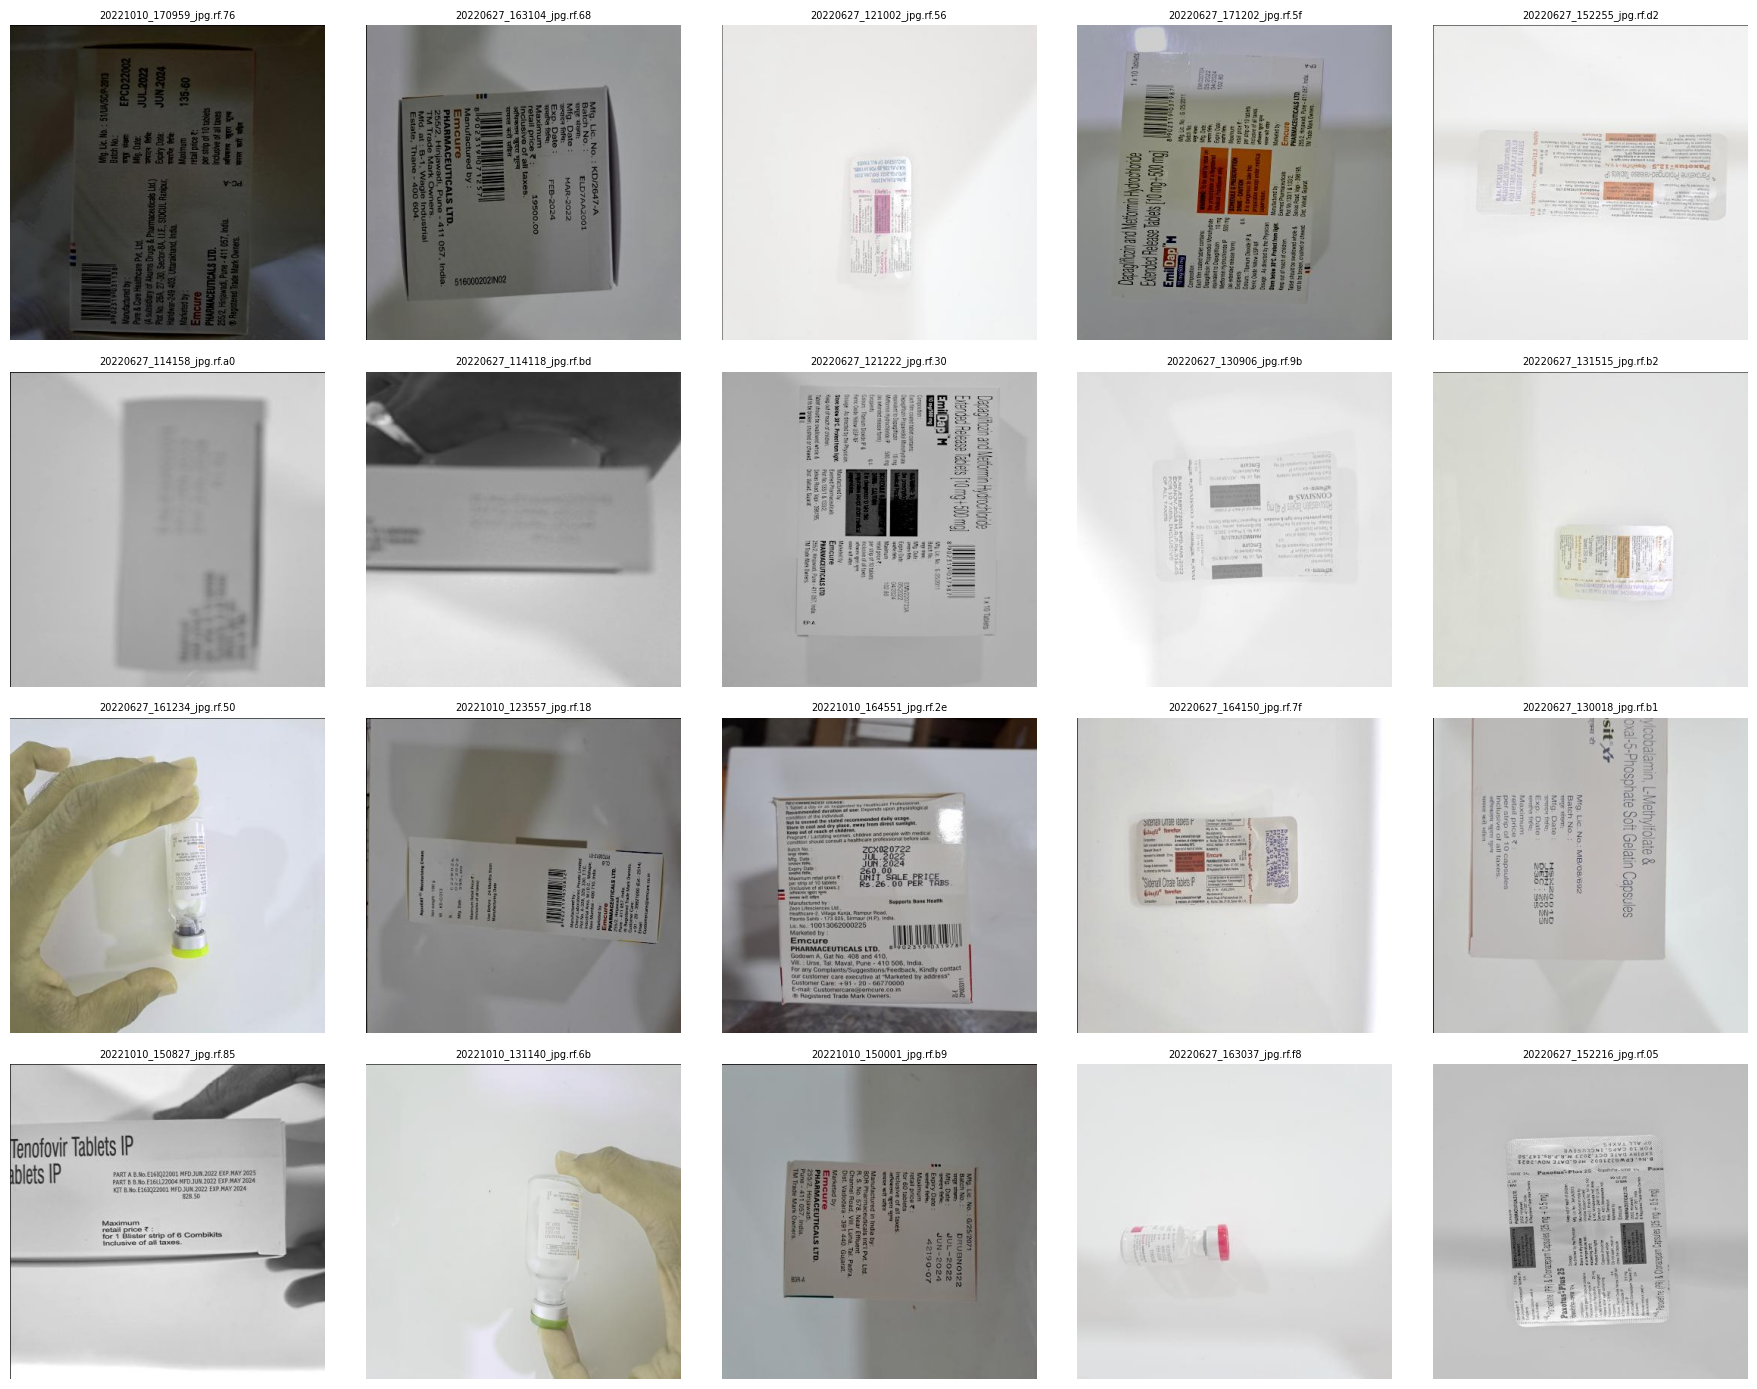

In [12]:
#images WITHOUT YOLO boxes

sample_images = random.sample(
    all_images,
    min(20, len(all_images))
)

fig, axes = plt.subplots(4, 5, figsize=(18, 14))
axes = axes.flatten()

for ax, image_path in zip(axes, sample_images):

    img = Image.open(image_path).convert("RGB")

    ax.imshow(img)
    ax.set_title(os.path.basename(image_path)[:25], fontsize=7)
    ax.axis("off")

plt.tight_layout()
plt.show()

Phase 2B — Detect the complete package:

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


def detect_package_bbox(image_path):
    """
    Estimate the bounding box of the pharmaceutical package.
    This is only a candidate detector; we will visually validate it.
    """

    img = cv2.imread(image_path)

    if img is None:
        return None

    h, w = img.shape[:2]

    # Resize for processing
    scale = min(800 / w, 800 / h, 1.0)

    if scale < 1:
        small = cv2.resize(
            img,
            (int(w * scale), int(h * scale))
        )
    else:
        small = img.copy()

    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)

    # Slight smoothing
    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    # detecting edges using canny
    edges = cv2.Canny(
        blur,
        40,
        120
    )

    #connecting broken edges
    kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT,
        (7, 7)
    )

    edges = cv2.morphologyEx(
        edges,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=2
    )

    # Find contours for fingind joining lines
    contours, _ = cv2.findContours(
        edges,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return (0, 0, w, h)

    candidates = []

    sh, sw = small.shape[:2]    #height and width ofresized image

    for contour in contours:

        x, y, cw, ch = cv2.boundingRect(contour)

        area = cw * ch
        image_area = sw * sh

        area_ratio = area / image_area
#candidate filtering based on region size
        # Ignoring tiny regions
        if area_ratio < 0.03:
            continue

        # Ignoring almost entire image
        if area_ratio > 0.95:
            continue

        candidates.append(
            (area, x, y, cw, ch)
        )

    if not candidates:
        return (0, 0, w, h)

    #choosing largest reasonable candidates
    candidates.sort(reverse=True)

    _, x, y, cw, ch = candidates[0]

    # converting back to original resolution
    x = int(x / scale)
    y = int(y / scale)
    cw = int(cw / scale)
    ch = int(ch / scale)

    # padding
    pad_x = int(0.05 * cw)
    pad_y = int(0.05 * ch)

    x1 = max(0, x - pad_x)
    y1 = max(0, y - pad_y)

    x2 = min(w, x + cw + pad_x)
    y2 = min(h, y + ch + pad_y)

    return (x1, y1, x2 - x1, y2 - y1)

Cell 19 — Visualize the detected package:

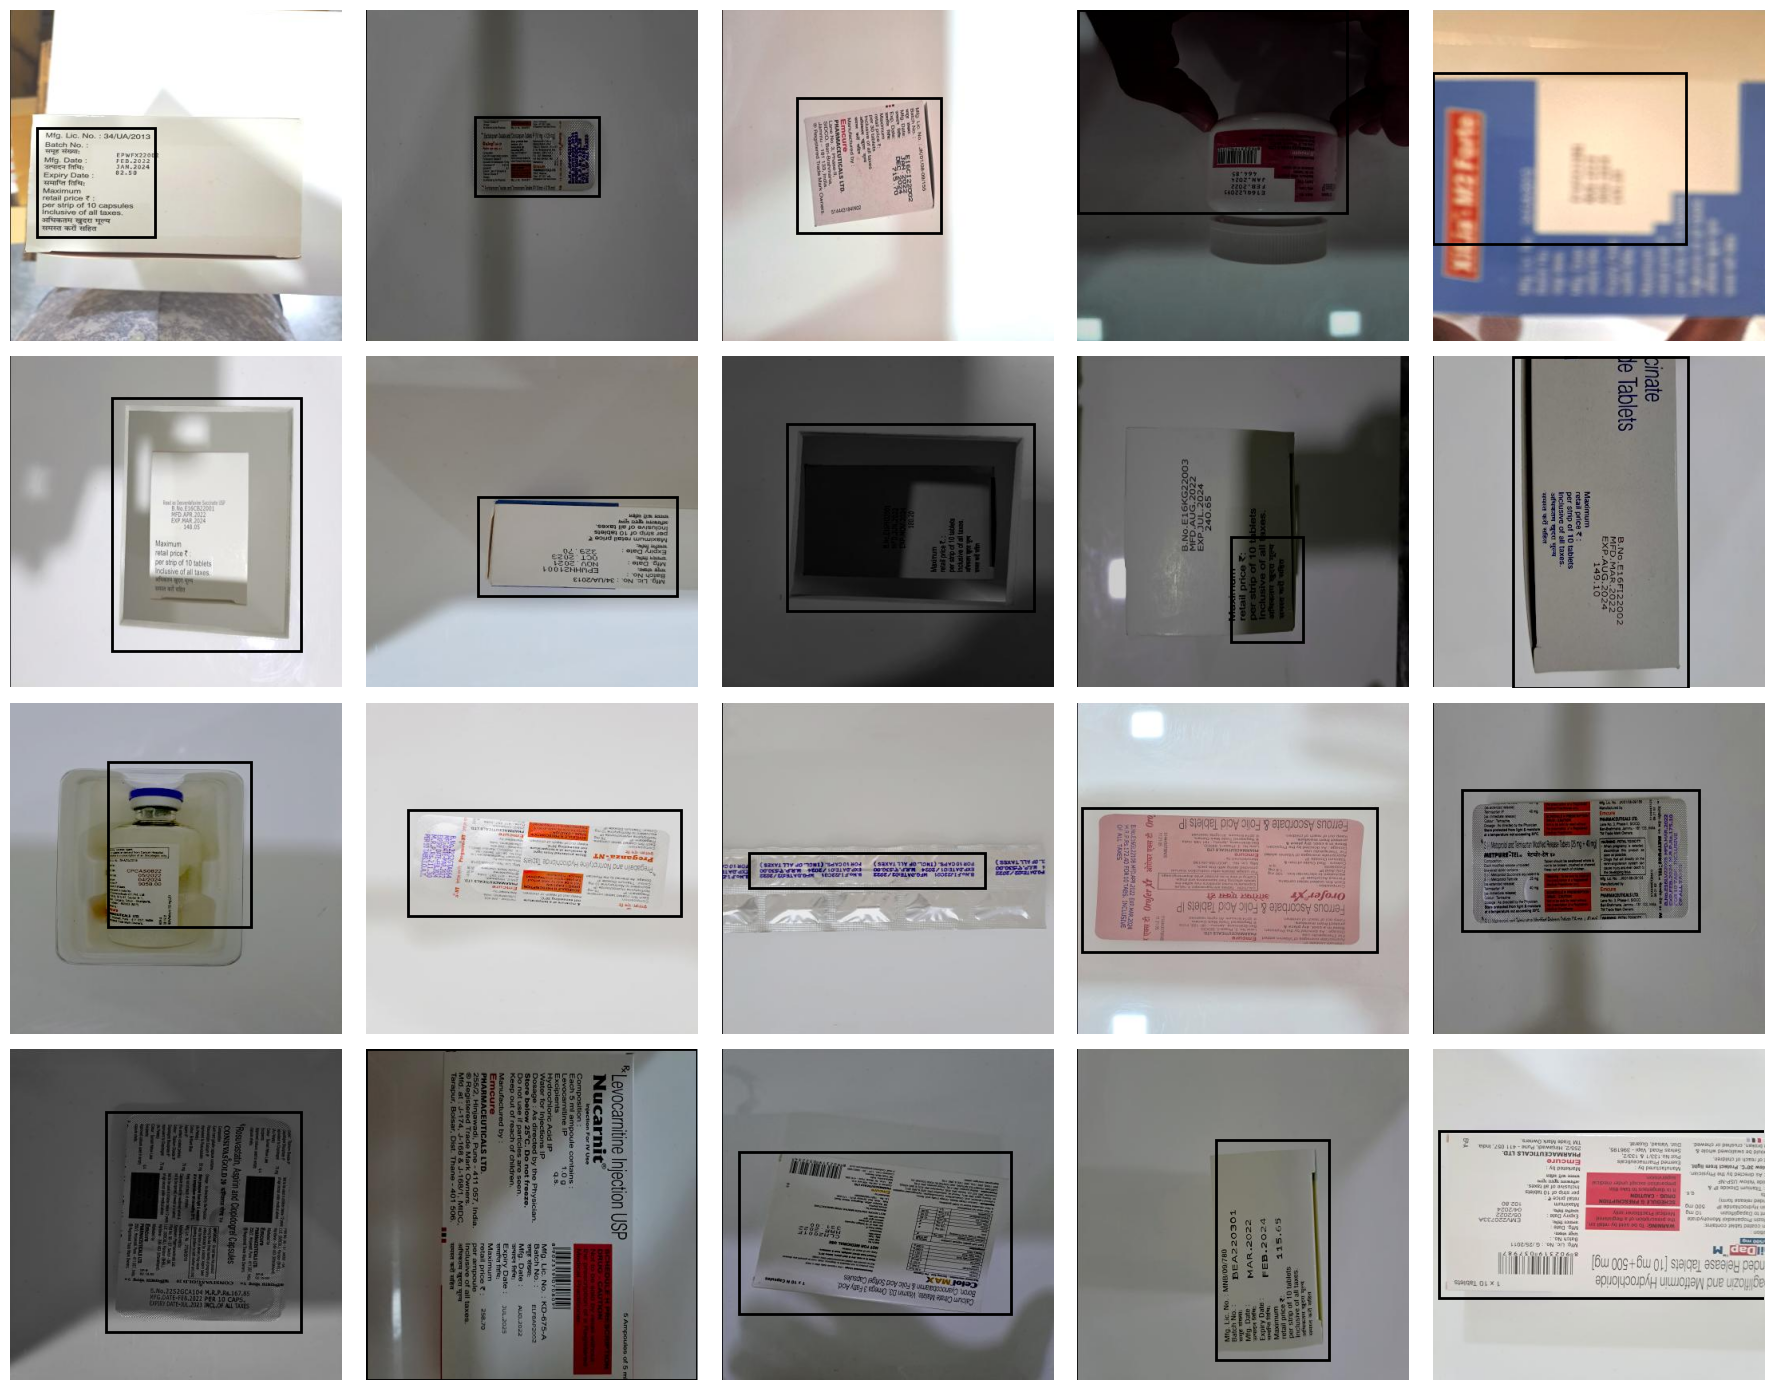

In [14]:
sample_images = random.sample(
    all_images,
    min(20, len(all_images))
)

fig, axes = plt.subplots(
    4, 5,
    figsize=(18, 14)
)

axes = axes.flatten()

for ax, image_path in zip(axes, sample_images):

    img = Image.open(image_path).convert("RGB")
    img_np = np.array(img)

    bbox = detect_package_bbox(image_path)

    ax.imshow(img_np)

    if bbox is not None:

        x, y, bw, bh = bbox

        rect = plt.Rectangle(
            (x, y),
            bw,
            bh,
            fill=False,
            linewidth=2
        )

        ax.add_patch(rect)

    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
# generating automatic crops for all

clean_dir = "/content/auto_clean"

os.makedirs(clean_dir, exist_ok=True)

crop_records = []

for i, image_path in enumerate(all_images):

    try:
        img = Image.open(image_path).convert("RGB")
        img_np = np.array(img)

        h, w = img_np.shape[:2]

        bbox = detect_package_bbox(image_path)

        if bbox is None:
            continue

        x, y, bw, bh = bbox

        # Rejecting obviously bad detections
        area_ratio = (bw * bh) / (w * h)

        if area_ratio < 0.03 or area_ratio > 0.95:
            continue

        # Crop
        crop = img.crop(
            (x, y, x + bw, y + bh)
        )


        output_name = f"clean_{i:05d}.jpg"
        output_path = os.path.join(
            clean_dir,
            output_name
        )

        crop.save(
            output_path,
            quality=95
        )

        crop_records.append({
            "original": image_path,
            "clean": output_path,
            "x": x,
            "y": y,
            "width": bw,
            "height": bh,
            "area_ratio": area_ratio
        })

    except Exception as e:
        print("Error:", image_path, e)

print("Original images:", len(all_images))
print("Successfully cropped:", len(crop_records))

Original images: 7709
Successfully cropped: 7000


In [16]:
# Cell 21 — Save crop metadata

crop_df = pd.DataFrame(crop_records)

crop_df.to_csv(
    "/content/auto_clean_metadata.csv",
    index=False
)

print(crop_df.head())
print("\nNumber of clean images:", len(crop_df))

                                            original  \
0  /content/emcure_raw/test/images/20220627_11450...   
1  /content/emcure_raw/test/images/20220627_11462...   
2  /content/emcure_raw/test/images/20220627_11531...   
3  /content/emcure_raw/test/images/20220627_11545...   
4  /content/emcure_raw/test/images/20220627_11554...   

                                 clean   x    y  width  height  area_ratio  
0  /content/auto_clean/clean_00000.jpg   0   38    416     215    0.516827  
1  /content/auto_clean/clean_00001.jpg   0  108    416     115    0.276442  
2  /content/auto_clean/clean_00003.jpg  47  169    344     155    0.308108  
3  /content/auto_clean/clean_00004.jpg   0  213    416     203    0.487981  
4  /content/auto_clean/clean_00005.jpg  57    0    359     336    0.697023  

Number of clean images: 7000


In [17]:
#seeing clean dataset

sample_records = random.sample(
    crop_records,
    min(100, len(crop_records))
)

fig, axes = plt.subplots(
    10, 10,
    figsize=(18, 18)
)

axes = axes.flatten()

for ax, record in zip(axes, sample_records):

    img = Image.open(record["clean"]).convert("RGB")

    ax.imshow(img)
    ax.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

# Phase-3 GEnerate the artificial damage

In [18]:
# create the 416 dataset folders in google drive

import os

dataset_root = "/content/drive/MyDrive/IE643-Project/dataset416"

clean_dir = os.path.join(dataset_root, "clean")
damaged_dir = os.path.join(dataset_root, "damaged")
mask_dir = os.path.join(dataset_root, "masks")

for directory in [clean_dir, damaged_dir, mask_dir]:
    os.makedirs(directory, exist_ok=True)

print("Dataset directory:", dataset_root)
for directory in [clean_dir, damaged_dir, mask_dir]:
    print(directory)

Dataset directory: /content/drive/MyDrive/IE643-Project/dataset416
/content/drive/MyDrive/IE643-Project/dataset416/clean
/content/drive/MyDrive/IE643-Project/dataset416/damaged
/content/drive/MyDrive/IE643-Project/dataset416/masks


defining damages ;

In [19]:
import numpy as np
import cv2
import random


def generate_rectangle_mask(h, w, severity=0.5):

    mask = np.zeros((h, w), dtype=np.uint8)

    # Damage area approximately 5–25% of image
    target_w = int(w * random.uniform(
        0.15 * severity,
        0.40 * severity + 0.10
    ))

    target_h = int(h * random.uniform(
        0.10 * severity,
        0.35 * severity + 0.10
    ))

    target_w = max(10, min(target_w, w))
    target_h = max(10, min(target_h, h))

    x = random.randint(
        0,
        max(0, w - target_w)
    )

    y = random.randint(
        0,
        max(0, h - target_h)
    )

    mask[
        y:y + target_h,
        x:x + target_w
    ] = 255

    return mask


def generate_irregular_mask(h, w, severity=0.5):

    mask = np.zeros((h, w), dtype=np.uint8)

    center_x = random.randint(
        int(0.2 * w),
        int(0.8 * w)
    )

    center_y = random.randint(
        int(0.2 * h),
        int(0.8 * h)
    )

    radius_x = random.randint(
        max(10, int(0.08 * w)),
        max(15, int(0.25 * w))
    )

    radius_y = random.randint(
        max(10, int(0.08 * h)),
        max(15, int(0.25 * h))
    )

    num_points = random.randint(8, 15)

    angles = np.linspace(
        0,
        2 * np.pi,
        num_points,
        endpoint=False
    )

    points = []

    for angle in angles:

        r_x = radius_x * random.uniform(0.6, 1.2)
        r_y = radius_y * random.uniform(0.6, 1.2)

        x = int(center_x + r_x * np.cos(angle))
        y = int(center_y + r_y * np.sin(angle))

        points.append([x, y])

    points = np.array(points, dtype=np.int32)

    cv2.fillPoly(
        mask,
        [points],
        255
    )

    return mask


def generate_brush_mask(h, w, severity=0.5):

    mask = np.zeros((h, w), dtype=np.uint8)

    x = random.randint(0, w - 1)
    y = random.randint(0, h - 1)

    num_strokes = random.randint(1, 4)

    for _ in range(num_strokes):

        x2 = np.clip(
            x + random.randint(
                -int(0.3 * w),
                int(0.3 * w)
            ),
            0,
            w - 1
        )

        y2 = np.clip(
            y + random.randint(
                -int(0.3 * h),
                int(0.3 * h)
            ),
            0,
            h - 1
        )

        thickness = random.randint(
            max(5, int(0.02 * min(h, w))),
            max(10, int(0.10 * min(h, w)))
        )

        cv2.line(
            mask,
            (x, y),
            (x2, y2),
            255,
            thickness
        )

        x, y = x2, y2

    return mask

applying the dmages

In [20]:
def apply_damage(clean, mask, damage_type):

    damaged = clean.copy()

    mask_bool = mask > 0

    if damage_type in ["cut", "tear", "paint"]:

        # using local mean color rather than pure black to maek more realistic dmages
        mean_color = np.mean(
            clean.reshape(-1, 3),
            axis=0
        ).astype(np.uint8)

        damaged[mask_bool] = mean_color

    elif damage_type == "blur":

        blurred = cv2.GaussianBlur(
            clean,
            (21, 21),
            0
        )

        damaged[mask_bool] = blurred[mask_bool]

    return damaged

In [21]:
def create_damage_example(clean_image, damage_type):

    h, w = clean_image.shape[:2]

    severity = random.uniform(
        0.5,
        1.0
    )

    if damage_type == "cut":

        mask = generate_rectangle_mask(
            h, w, severity
        )

    elif damage_type == "tear":

        mask = generate_irregular_mask(
            h, w, severity
        )

    elif damage_type == "paint":

        mask = generate_brush_mask(
            h, w, severity
        )

    elif damage_type == "blur":

        # Bluring uses irregular region
        mask = generate_irregular_mask(
            h, w, severity
        )

    else:
        raise ValueError(
            f"Unknown damage type: {damage_type}"
        )

    damaged = apply_damage(
        clean_image,
        mask,
        damage_type
    )

    return damaged, mask

In [22]:
#testing

damage_types = [
    "cut",
    "tear",
    "paint",
    "blur"
]

test_records = []

sample_records = random.sample(
    crop_records,
    min(20, len(crop_records))
)

for i, record in enumerate(sample_records):

    clean = np.array(
        Image.open(record["clean"]).convert("RGB")
    )

    damage_type = damage_types[
        i % len(damage_types)
    ]

    damaged, mask = create_damage_example(
        clean,
        damage_type
    )

    test_records.append({
        "clean": clean,
        "damaged": damaged,
        "mask": mask,
        "damage_type": damage_type
    })

print("Generated:", len(test_records))

Generated: 20


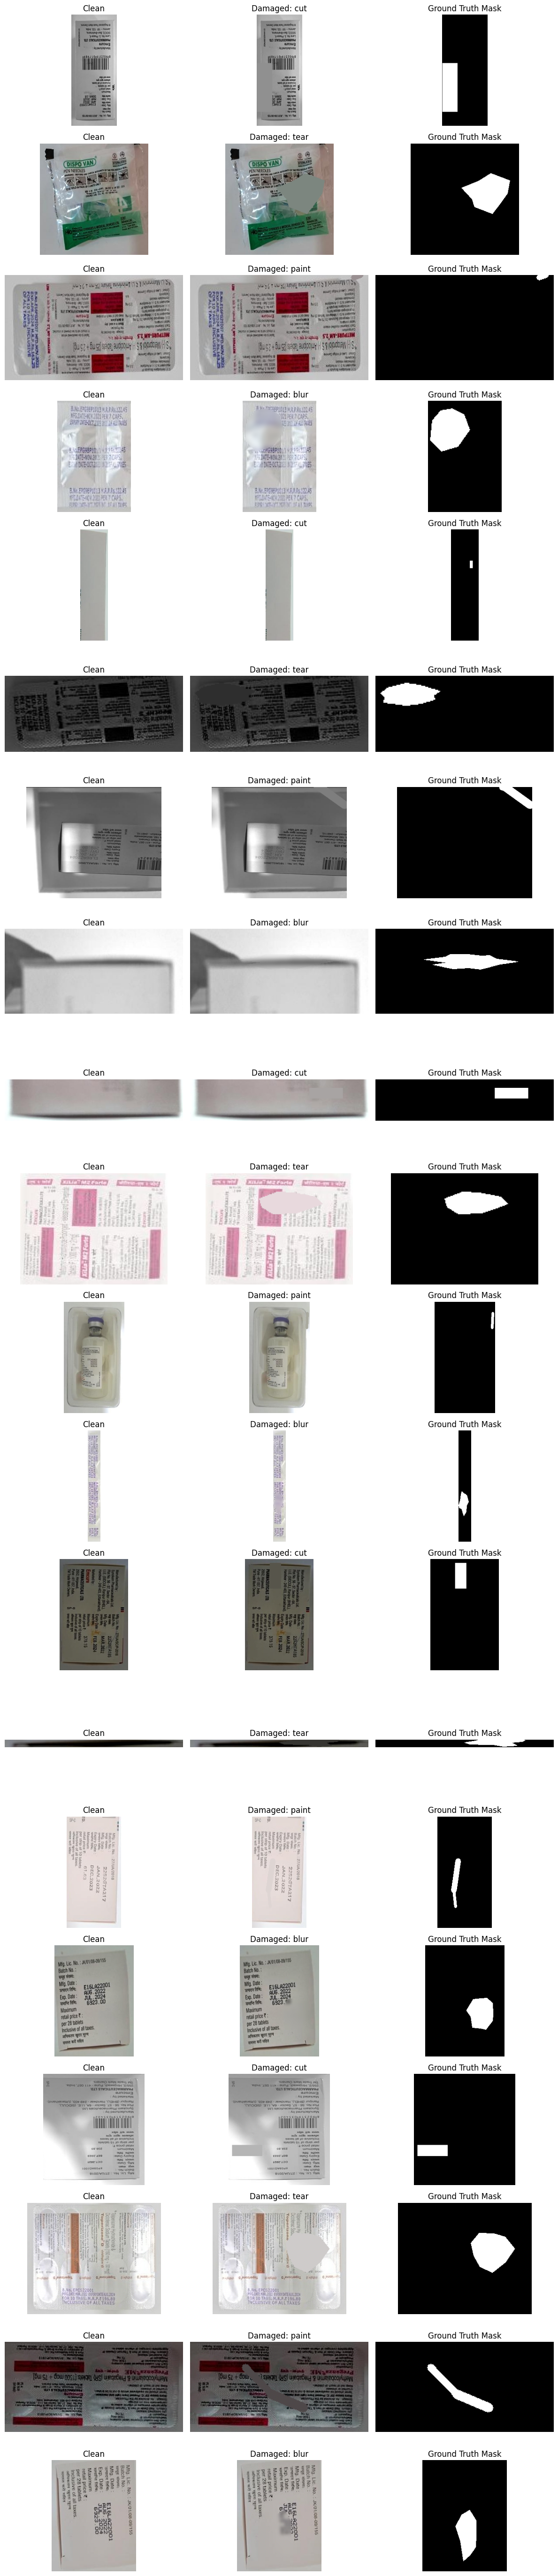

In [23]:
fig, axes = plt.subplots(
    20,
    3,
    figsize=(12, 55)
)

for i, record in enumerate(test_records):

    axes[i, 0].imshow(record["clean"])
    axes[i, 0].set_title("Clean")

    axes[i, 1].imshow(record["damaged"])
    axes[i, 1].set_title(
        "Damaged: " + record["damage_type"]
    )

    axes[i, 2].imshow(
        record["mask"],
        cmap="gray"
    )
    axes[i, 2].set_title("Ground Truth Mask")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

GENERATING FINAL DATASET:

## Generate the final 416×416 dataset

This notebook creates the clean images, damaged images, masks, and `metadata.csv` in `MyDrive/IE643-Project/dataset416`. It does **not** create train/validation/test splits; the U-Net notebook will handle splitting by original source image.

**Important:** `RESET_DATASET = True` clears existing `clean`, `damaged`, and `masks` contents and `metadata.csv` inside `dataset416` before rebuilding them. It does not delete other files or folders in `IE643-Project`.

In [24]:
# final paired reconstruction dataset at 416x416


import os
import random
import numpy as np
import pandas as pd
import cv2

from PIL import Image


# Configuration


random.seed(643)
np.random.seed(643)

NUM_VARIANTS_PER_IMAGE = 3
IMAGE_SIZE = 416

DATASET_ROOT = "/content/drive/MyDrive/IE643-Project/dataset416"

CLEAN_DIR = os.path.join(DATASET_ROOT, "clean")
DAMAGED_DIR = os.path.join(DATASET_ROOT, "damaged")
MASK_DIR = os.path.join(DATASET_ROOT, "masks")
METADATA_PATH = os.path.join(DATASET_ROOT, "metadata.csv")

# clear only previous generated dataset files to avoid stale samples
RESET_DATASET = True

if RESET_DATASET:
    for directory in [CLEAN_DIR, DAMAGED_DIR, MASK_DIR]:
        if os.path.isdir(directory):
            shutil.rmtree(directory)

    if os.path.isfile(METADATA_PATH):
        os.remove(METADATA_PATH)

for directory in [CLEAN_DIR, DAMAGED_DIR, MASK_DIR]:
    os.makedirs(directory, exist_ok=True)

print("Dataset output:", DATASET_ROOT)
print("Image size:", IMAGE_SIZE)
print("Variants per clean image:", NUM_VARIANTS_PER_IMAGE)


def letterbox_image(image, size=416, background=255):

    h, w = image.shape[:2]

    scale = min(size / w, size / h)

    new_w = max(1, int(w * scale))
    new_h = max(1, int(h * scale))

    resized = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    canvas = np.ones(
        (size, size, 3),
        dtype=np.uint8
    ) * background

    x = (size - new_w) // 2
    y = (size - new_h) // 2

    canvas[
        y:y + new_h,
        x:x + new_w
    ] = resized

    return canvas



# Generate rectangular cut mask


def generate_cut_mask(h, w):

    mask = np.zeros(
        (h, w),
        dtype=np.uint8
    )


    x1 = random.randint(
        int(0.05 * w),
        int(0.60 * w)
    )

    y1 = random.randint(
        int(0.05 * h),
        int(0.60 * h)
    )

    damage_w = random.randint(
        int(0.15 * w),
        int(0.40 * w)
    )

    damage_h = random.randint(
        int(0.10 * h),
        int(0.35 * h)
    )

    x2 = min(w, x1 + damage_w)
    y2 = min(h, y1 + damage_h)

    mask[y1:y2, x1:x2] = 255

    return mask



# Generate irregular tear mask


def generate_tear_mask(h, w):

    mask = np.zeros(
        (h, w),
        dtype=np.uint8
    )

    center_x = random.randint(
        int(0.25 * w),
        int(0.75 * w)
    )

    center_y = random.randint(
        int(0.25 * h),
        int(0.75 * h)
    )

    radius_x = random.randint(
        int(0.10 * w),
        int(0.25 * w)
    )

    radius_y = random.randint(
        int(0.08 * h),
        int(0.25 * h)
    )

    n_points = random.randint(8, 14)

    angles = np.linspace(
        0,
        2 * np.pi,
        n_points,
        endpoint=False
    )

    points = []

    for angle in angles:

        rx = radius_x * random.uniform(
            0.65, 1.25
        )

        ry = radius_y * random.uniform(
            0.65, 1.25
        )

        x = int(
            center_x + rx * np.cos(angle)
        )

        y = int(
            center_y + ry * np.sin(angle)
        )

        points.append([x, y])

    points = np.array(
        points,
        dtype=np.int32
    )

    cv2.fillPoly(
        mask,
        [points],
        255
    )

    return mask



# Generate paint / occlusion mask


def generate_paint_mask(h, w):

    mask = np.zeros(
        (h, w),
        dtype=np.uint8
    )

    n_strokes = random.randint(1, 4)

    for _ in range(n_strokes):

        x1 = random.randint(
            int(0.05 * w),
            int(0.85 * w)
        )

        y1 = random.randint(
            int(0.05 * h),
            int(0.85 * h)
        )

        x2 = np.clip(
            x1 + random.randint(
                -int(0.25 * w),
                int(0.25 * w)
            ),
            0,
            w - 1
        )

        y2 = np.clip(
            y1 + random.randint(
                -int(0.20 * h),
                int(0.20 * h)
            ),
            0,
            h - 1
        )

        thickness = random.randint(
            max(5, int(0.025 * min(h, w))),
            max(8, int(0.08 * min(h, w)))
        )

        cv2.line(
            mask,
            (x1, y1),
            (x2, y2),
            255,
            thickness
        )

    #soften the boundary
    kernel = np.ones((3, 3), np.uint8)

    mask = cv2.dilate(
        mask,
        kernel,
        iterations=1
    )

    return mask


# damage mask


def generate_damage_mask(
    h,
    w,
    damage_type
):

    if damage_type == "cut":

        return generate_cut_mask(h, w)

    elif damage_type == "tear":

        return generate_tear_mask(h, w)

    elif damage_type == "paint":

        return generate_paint_mask(h, w)

    elif damage_type == "blur":

        # Irregular region for local blur
        return generate_tear_mask(h, w)

    elif damage_type == "combined":

        mask1 = generate_tear_mask(h, w)
        mask2 = generate_paint_mask(h, w)

        return cv2.bitwise_or(
            mask1,
            mask2
        )

    else:

        raise ValueError(
            f"Unknown damage type: {damage_type}"
        )



#Applying damage
def apply_damage(
    clean,
    mask,
    damage_type
):

    damaged = clean.copy()

    mask_bool = mask > 0

    if damage_type == "cut":


        blurred = cv2.GaussianBlur(
            clean,
            (31, 31),
            0
        )

        damaged[mask_bool] = blurred[mask_bool]

    elif damage_type == "tear":

        # Approximating missing/covered region
        blurred = cv2.GaussianBlur(
            clean,
            (41, 41),
            0
        )

        damaged[mask_bool] = blurred[mask_bool]

    elif damage_type == "paint":

        #Opaque whiteish obstruction
        local_mean = np.mean(
            clean,
            axis=(0, 1)
        ).astype(np.uint8)

        damaged[mask_bool] = local_mean

    elif damage_type == "blur":

        blurred = cv2.GaussianBlur(
            clean,
            (31, 31),
            0
        )

        damaged[mask_bool] = blurred[mask_bool]

    elif damage_type == "combined":

        blurred = cv2.GaussianBlur(
            clean,
            (31, 31),
            0
        )

        damaged[mask_bool] = blurred[mask_bool]

    return damaged

# Determine damage bounding box

def mask_bbox(mask):

    ys, xs = np.where(mask > 0)

    if len(xs) == 0:

        return (
            0, 0, 0, 0
        )

    x1 = int(xs.min())
    y1 = int(ys.min())
    x2 = int(xs.max())
    y2 = int(ys.max())

    return (
        x1,
        y1,
        x2,
        y2
    )



#Select damage types
damage_types = [
    "cut",
    "tear",
    "paint",
    "blur",
    "combined"
]

# Generate dataset
records = []

total_clean = len(crop_records)

print("Starting dataset generation...")
print("Clean source images:", total_clean)
print("Variants per image:", NUM_VARIANTS_PER_IMAGE)
print(
    "Maximum damaged samples:",
    total_clean * NUM_VARIANTS_PER_IMAGE
)

for idx, record in enumerate(crop_records):

    try:

        # Read original automatic crop

        clean_original = np.array(
            Image.open(
                record["clean"]
            ).convert("RGB")
        )
          # resize to 416x416
        clean = letterbox_image(
            clean_original,
            size=IMAGE_SIZE
        )

        source_name = os.path.splitext(
            os.path.basename(
                record["original"]
            )
        )[0]

       # Save standardized clean image ONCE


        clean_name = (
            f"{idx:06d}_clean.jpg"
        )

        clean_path = os.path.join(
            CLEAN_DIR,
            clean_name
        )

        Image.fromarray(
            clean
        ).save(
            clean_path,
            quality=95
        )


        #GENERATE VARIANTS

        selected_types = random.sample(
            damage_types,
            NUM_VARIANTS_PER_IMAGE
        )

        for variant_idx, damage_type in enumerate(
            selected_types
        ):

            h, w = clean.shape[:2]

            mask = generate_damage_mask(
                h,
                w,
                damage_type
            )

            # Skip extremely tiny masks
            mask_ratio = np.mean(
                mask > 0
            )

            if mask_ratio < 0.01:
                continue

            # Avoid enormous masks
            if mask_ratio > 0.40:
                continue

            damaged = apply_damage(
                clean,
                mask,
                damage_type
            )

            sample_id = (
                f"{idx:06d}_{variant_idx:02d}"
            )

            damaged_name = (
                f"{sample_id}_{damage_type}.jpg"
            )

            mask_name = (
                f"{sample_id}_{damage_type}.png"
            )

            damaged_path = os.path.join(
                DAMAGED_DIR,
                damaged_name
            )

            mask_path = os.path.join(
                MASK_DIR,
                mask_name
            )

            Image.fromarray(
                damaged
            ).save(
                damaged_path,
                quality=95
            )

            Image.fromarray(
                mask
            ).save(
                mask_path
            )


            # amage bounding box

            x1, y1, x2, y2 = mask_bbox(
                mask
            )

            bbox_w = x2 - x1
            bbox_h = y2 - y1

            records.append({

                "sample_id": sample_id,

                "source_image": source_name,

                "clean_image": clean_path,

                "damaged_image": damaged_path,

                "mask": mask_path,

                "damage_type": damage_type,

                "mask_area_ratio": mask_ratio,

                "mask_x1": x1,
                "mask_y1": y1,
                "mask_x2": x2,
                "mask_y2": y2,

                "mask_bbox_width": bbox_w,
                "mask_bbox_height": bbox_h,

                "image_width": w,
                "image_height": h
            })

        # Progress
        if (idx + 1) % 250 == 0:

            print(
                f"Processed "
                f"{idx + 1}/{total_clean} "
                f"clean images | "
                f"generated {len(records)} samples"
            )

    except Exception as e:

        print(
            "ERROR:",
            record["original"],
            e
        )

# Save metadata
metadata_df = pd.DataFrame(records)

metadata_path = METADATA_PATH

metadata_df.to_csv(
    metadata_path,
    index=False
)

print("\n===================================")
print("DATASET GENERATION COMPLETE")
print("===================================")

print(
    "Clean images:",
    len(
        os.listdir(CLEAN_DIR)
    )
)

print(
    "Damaged samples:",
    len(metadata_df)
)

print(
    "Metadata:",
    metadata_path
)

print("Splits were not created; the U-Net notebook will create the split manifest.")


Dataset output: /content/drive/MyDrive/IE643-Project/dataset416
Image size: 416
Variants per clean image: 3
Starting dataset generation...
Clean source images: 7000
Variants per image: 3
Maximum damaged samples: 21000
Processed 250/7000 clean images | generated 735 samples
Processed 500/7000 clean images | generated 1475 samples
Processed 750/7000 clean images | generated 2212 samples
Processed 1000/7000 clean images | generated 2954 samples
Processed 1250/7000 clean images | generated 3687 samples
Processed 1500/7000 clean images | generated 4428 samples
Processed 1750/7000 clean images | generated 5164 samples
Processed 2000/7000 clean images | generated 5900 samples
Processed 2250/7000 clean images | generated 6629 samples
Processed 2500/7000 clean images | generated 7357 samples
Processed 2750/7000 clean images | generated 8097 samples
Processed 3000/7000 clean images | generated 8837 samples
Processed 3250/7000 clean images | generated 9579 samples
Processed 3500/7000 clean images

In [25]:
print(metadata_df["damage_type"].value_counts())

print("\nMask area statistics:")
print(
    metadata_df["mask_area_ratio"].describe()
)

damage_type
combined    4248
tear        4240
blur        4221
cut         4129
paint       3814
Name: count, dtype: int64

Mask area statistics:
count    20652.000000
mean         0.072745
std          0.037404
min          0.010003
25%          0.043581
50%          0.066623
75%          0.097486
max          0.236022
Name: mask_area_ratio, dtype: float64


OUR FINAL DATSET VISUALISATION:

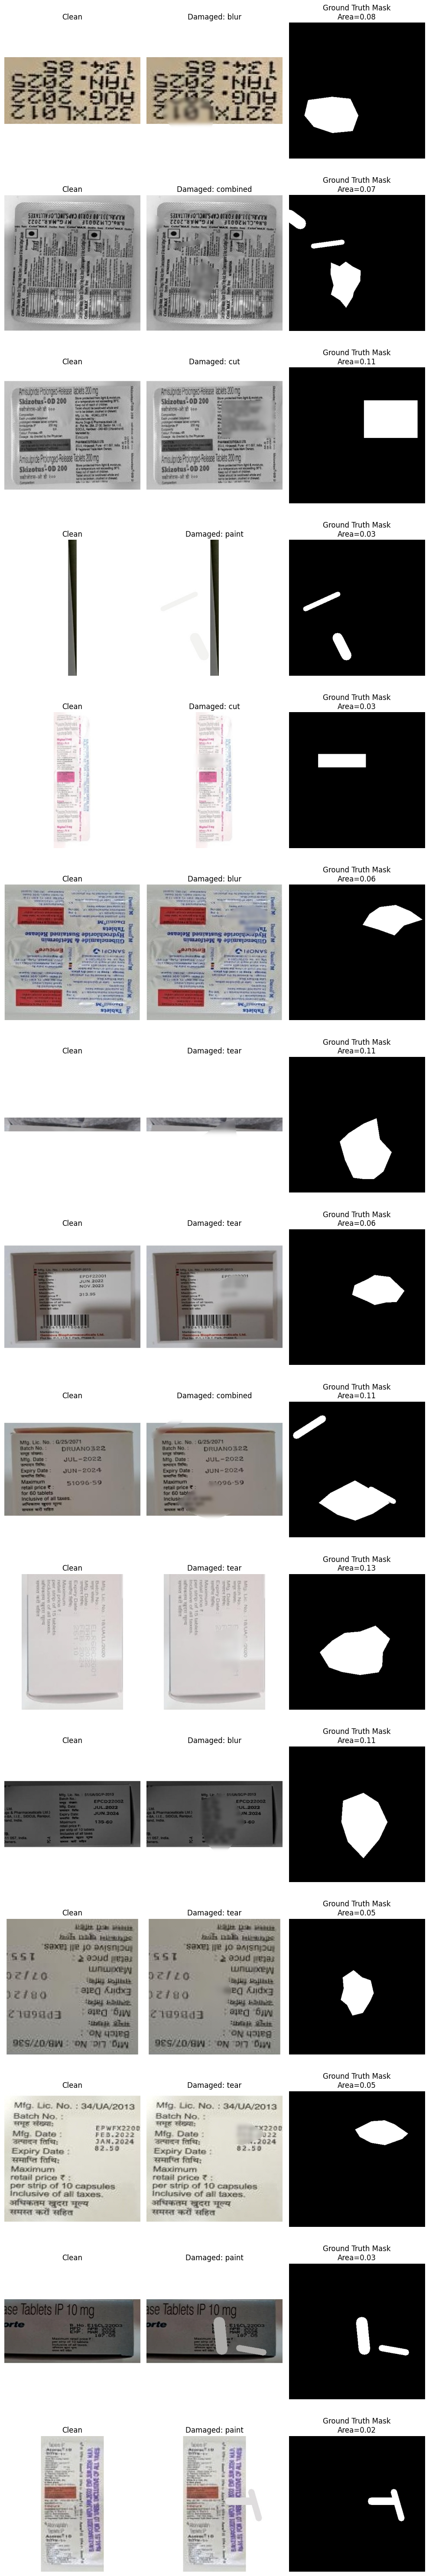

In [26]:
sample_df = metadata_df.sample(
    min(15, len(metadata_df)),
    random_state=643
)

fig, axes = plt.subplots(
    len(sample_df),
    3,
    figsize=(10, 4 * len(sample_df))
)

if len(sample_df) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, (_, item) in enumerate(
    sample_df.iterrows()
):

    clean = np.array(
        Image.open(
            item["clean_image"]
        ).convert("RGB")
    )

    damaged = np.array(
        Image.open(
            item["damaged_image"]
        ).convert("RGB")
    )

    mask = np.array(
        Image.open(
            item["mask"]
        )
    )

    axes[row, 0].imshow(clean)
    axes[row, 0].set_title("Clean")

    axes[row, 1].imshow(damaged)
    axes[row, 1].set_title(
        f"Damaged: {item['damage_type']}"
    )

    axes[row, 2].imshow(
        mask,
        cmap="gray"
    )
    axes[row, 2].set_title(
        f"Ground Truth Mask\n"
        f"Area={item['mask_area_ratio']:.2f}"
    )

    for col in range(3):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()